# CPS 3830 Final Project (Fall 2026) - Task 1
## Data Loading, Preprocessing, and Initial Exploration
**Dataset:** Used car listings (`UsedCarInfo.csv`, prices in Bangladeshi Taka, Tk)  
**Team members:** _Name 1_, _Name 2_  
**Learning goal (Task 3):** Regression - predict a car's listing price from its attributes.

**Notebook outline**
1. Load the data and inspect it (shape, features, target, missing values)
2. Clean and preprocess (parsing, duplicates, outliers, hidden missing values)
3. Feature engineering (optional)
4. Encoding and normalization
5. Visualizations
6. Summary of observations

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_PATH = "UsedCarInfo.csv"

## 1. Load and explore the dataset

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df_raw.shape)
print("Feature names:", list(df_raw.columns))
df_raw.head()

Shape (rows, columns): (5997, 10)
Feature names: ['title', 'brand', 'model', 'transmission', 'fuel_type', 'price', 'year_of_manufacture', 'energy_capacity', 'kilometers_run', 'car_age']


,title,brand,model,transmission,fuel_type,price,year_of_manufacture,energy_capacity,kilometers_run,car_age
0,Toyota Corolla CR 13.REG 1999.MODEL 1996,Toyota,Corolla,Automatic,"CNG, Octane","Tk 530,000",1996,"1,500 cc","89,000 km",30
1,Toyota Corolla Cross 2023,Toyota,Corolla Cross,Automatic,"Hybrid, Octane","Tk 5,500,000",2025,"1,800 cc","15,500 km",1
2,Toyota RAV4 CR 13.REG 2011.MODEL 2005,Toyota,RAV4,Automatic,"Octane, LPG","Tk 1,370,000",2005,"1,800 cc","87,000 km",21
3,Toyota Allion CR 23.REG 2010.MODEL 2004,Toyota,Allion,Automatic,"CNG, Octane","Tk 1,350,000",2004,"1,500 cc","89,000 km",22
4,Toyota Hiace 2015,Toyota,Hiace,Automatic,"CNG, Octane","Tk 2,750,000",2020,"2,000 cc","190,000 km",6


In [3]:
# Data types, missing values, and number of distinct values per column
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_missing (NaN)": df_raw.isna().sum(),
    "n_unique": df_raw.nunique(),
    "example": df_raw.iloc[0],
})
overview

,dtype,n_missing (NaN),n_unique,example
title,str,0,4656,Toyota Corolla CR 13.REG 1999.MODEL 1996
brand,str,0,33,Toyota
model,str,0,168,Corolla
transmission,str,0,2,Automatic
fuel_type,str,0,35,"CNG, Octane"
price,str,0,893,"Tk 530,000"
year_of_manufacture,int64,0,38,1996
energy_capacity,str,0,68,"1,500 cc"
kilometers_run,str,0,2833,"89,000 km"
car_age,int64,0,38,30


**Target.** The raw data has no class labels. The target is the continuous column **`price`**, so this is a **regression** problem. 
Several features (`price`, `energy_capacity`, `kilometers_run`) are stored as text such as `"Tk 530,000"` or `"1,500 cc"` and must be parsed into numbers.
There are no `NaN` values, but that does not mean the data is clean, so we check for *hidden* problems next.

In [4]:
# Hidden data-quality problems that plain-NaN checks would miss
bad_cc = df_raw[~df_raw["energy_capacity"].str.fullmatch(r"[\d,]+ cc")]
print("energy_capacity values that are not in '<number> cc' format:")
print(bad_cc[["title", "energy_capacity"]].to_string(), "\n")

dup_mask = df_raw.drop(columns="title").duplicated()
print("Rows identical to an earlier row in every column except the free-text title:", dup_mask.sum())
print("Distinct fuel_type strings:", df_raw["fuel_type"].nunique(), "(multi-fuel combos like 'Petrol, Hybrid, Octane')")
print("transmission split:\n", df_raw["transmission"].value_counts().to_string())

energy_capacity values that are not in '<number> cc' format:
                                  title                    energy_capacity
5838  Toyota Passo 2005 reg 2010 1000cc  Toyota Passo 2005 reg 2010 1000cc 

Rows identical to an earlier row in every column except the free-text title: 104
Distinct fuel_type strings: 35 (multi-fuel combos like 'Petrol, Hybrid, Octane')
transmission split:
 transmission
Automatic    5937
Manual         60


## 2. Preprocessing

Steps, in order:
1. **Parse text columns** into numbers (`price`, `kilometers_run`, `energy_capacity`).
2. **Remove repost duplicates** (identical in every column except the title). Removing them *before* any train/test split matters: otherwise the same car can appear in both train and test and inflate scores.
3. **Fix implausible values**: engine sizes under 600 cc (typos, or an electric car) and near-zero mileage on cars that are 2+ years old are treated as missing and imputed. Prices under 100,000 Tk are dropped as mis-entered listings.
4. **Outlier handling**: winsorize numeric *features* at the 1st/99th percentile. `price` is *not* clipped (a Rolls-Royce really does cost 105M Tk); we model it on a log scale instead.

In [5]:
df = df_raw.copy()

# 1. Parse text -> numbers
df["price"] = df["price"].str.replace(r"[^\d]", "", regex=True).astype(float)
df["kilometers_run"] = df["kilometers_run"].str.replace(r"[^\d]", "", regex=True).astype(float)
# extract the number before 'cc' (also rescues the one corrupted row that ends in '1000cc')
cc = df["energy_capacity"].str.extract(r"([\d,]+)\s*cc", flags=re.I)[0]
df["engine_cc"] = cc.str.replace(",", "").astype(float)
df = df.drop(columns="energy_capacity")

# 2. Remove repost duplicates (keep the first listing)
n0 = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "title"]).copy()
print(f"Duplicates removed: {n0 - len(df)}  ->  {len(df)} rows left")

# 3a. Implausible prices
bad_price = df["price"] < 100_000
print("Implausible prices dropped:", bad_price.sum())
print(df.loc[bad_price, ["title", "price", "kilometers_run"]].to_string())
df = df[~bad_price].copy()

# 3b. Hidden missing values -> NaN, then impute
bad_cc = df["engine_cc"] < 600                                    # 50 cc and 150 cc cars are not real
bad_km = (df["kilometers_run"] < 100) & (df["car_age"] >= 2)      # near-zero mileage on an old car
print("Implausible engine_cc (set to NaN):", bad_cc.sum())
print("Implausible kilometers_run (set to NaN):", bad_km.sum())
df.loc[bad_cc, "engine_cc"] = np.nan
df.loc[bad_km, "kilometers_run"] = np.nan

# engine size: median of the same car model, else overall median
df["engine_cc"] = df["engine_cc"].fillna(df.groupby("model")["engine_cc"].transform("median")).fillna(df["engine_cc"].median())
# mileage: median of cars with the same age, else overall median
df["kilometers_run"] = df["kilometers_run"].fillna(df.groupby("car_age")["kilometers_run"].transform("median")).fillna(df["kilometers_run"].median())
print("Remaining NaNs:", int(df[["engine_cc", "kilometers_run", "price"]].isna().sum().sum()))

Duplicates removed: 104  ->  5893 rows left
Implausible prices dropped: 2
                                   title     price  kilometers_run
3027                         Suzuki 2026 75,000.00       46,000.00
3556  Honda Vezel E PLAY PUSH START 2021 46,189.00       23,134.00
Implausible engine_cc (set to NaN): 2
Implausible kilometers_run (set to NaN): 30
Remaining NaNs: 0


### 2b. Outlier analysis
We flag outliers with the 1.5 x IQR rule, then winsorize the numeric features. We first look at the extremes.

In [6]:
df["km_per_year"] = df["kilometers_run"] / df["car_age"].clip(lower=1)   # engineered below (needed here for the report)

def iqr_report(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"min": s.min(), "median": s.median(), "max": s.max(),
                      "IQR low fence": lo, "IQR high fence": hi,
                      "n outliers": int(((s < lo) | (s > hi)).sum()),
                      "% outliers": 100 * ((s < lo) | (s > hi)).mean()})

num_cols = ["car_age", "kilometers_run", "engine_cc", "km_per_year"]
pd.DataFrame({c: iqr_report(df[c]) for c in num_cols + ["price"]}).T

,min,median,max,IQR low fence,IQR high fence,n outliers,% outliers
car_age,1.00,6.00,65.00,0.50,12.50,970.00,16.47
kilometers_run,0.00,"63,500.00","950,000.00","-16,750.00","142,850.00",138.00,2.34
engine_cc,660.00,"1,800.00","5,700.00",750.00,"2,750.00",101.00,1.71
km_per_year,0.00,"8,850.00","209,000.00","-7,208.33","25,125.00",99.00,1.68
price,"145,000.00","3,380,000.00","105,000,000.00","-710,000.00","7,450,000.00",419.00,7.11


In [7]:
# Winsorize numeric features at the 1st / 99th percentile (target 'price' is left untouched)
for c in num_cols:
    lo, hi = df[c].quantile([0.01, 0.99])
    n_clipped = int(((df[c] < lo) | (df[c] > hi)).sum())
    df[c] = df[c].clip(lo, hi)
    print(f"{c:15s} clipped to [{lo:,.1f}, {hi:,.1f}]  ({n_clipped} values changed)")

car_age         clipped to [1.0, 29.0]  (54 values changed)
kilometers_run  clipped to [20.0, 186,000.0]  (116 values changed)
engine_cc       clipped to [1,300.0, 3,000.0]  (82 values changed)
km_per_year     clipped to [20.0, 29,600.0]  (116 values changed)


## 3. Feature engineering (optional)
- `log_price` = log(1 + price): the price is heavily right-skewed, so the log target is much easier for regression models.
- `km_per_year` = mileage / age: separates a heavily driven car from an old but barely used one.
- **Multi-hot fuel flags**: `fuel_type` has 35 combination strings (`"Petrol, Hybrid, Octane"`). We split it into one 0/1 flag per fuel so the information is shared across combinations.
- `is_manual`: binary version of `transmission`.
- **Rare-category grouping**: `brand` (33 values) and `model` (168 values) are long-tailed; we keep frequent categories and group the rest as `Other` to avoid a huge sparse one-hot matrix.
- `price_tier`: quartile bins of price (Budget / Mid / Upper-mid / Premium). It is only a convenience label for coloring plots in Task 2 and for a possible classification/hybrid goal.
- Dropped: `title` (free text, repeats info from other columns) and `year_of_manufacture` (perfectly redundant with `car_age`, correlation of -1).

In [8]:
df["log_price"] = np.log1p(df["price"])
df["is_manual"] = (df["transmission"] == "Manual").astype(int)

# multi-hot fuel flags
fuel = df["fuel_type"].str.get_dummies(sep=", ")
fuel["Other"] = fuel[["Other fuel type", "Unknown"]].max(axis=1)
fuel = fuel.drop(columns=["Other fuel type", "Unknown"]).add_prefix("fuel_")
df = pd.concat([df, fuel], axis=1)
fuel_cols = list(fuel.columns)

# group rare brands / models
def group_rare(s, min_count):
    keep = s.value_counts()[lambda v: v >= min_count].index
    return s.where(s.isin(keep), "Other")
df["brand_group"] = group_rare(df["brand"], 15)
df["model_group"] = group_rare(df["model"], 30)
print("brand_group levels:", df["brand_group"].nunique(), "| model_group levels:", df["model_group"].nunique())

df["price_tier"] = pd.qcut(df["price"], 4, labels=["Budget", "Mid", "Upper-mid", "Premium"])

df = df.drop(columns=["title", "year_of_manufacture"])
print("Fuel flag counts:"); print(df[fuel_cols].sum().to_string())
df.head()

brand_group levels: 11 | model_group levels: 27
Fuel flag counts:
fuel_CNG          505
fuel_Diesel        71
fuel_Electric       6
fuel_Hybrid      2793
fuel_LPG          189
fuel_Octane      4352
fuel_Petrol      2423
fuel_Other         48


,brand,model,transmission,fuel_type,price,kilometers_run,car_age,engine_cc,km_per_year,log_price,is_manual,fuel_CNG,fuel_Diesel,fuel_Electric,fuel_Hybrid,fuel_LPG,fuel_Octane,fuel_Petrol,fuel_Other,brand_group,model_group,price_tier
0,Toyota,Corolla,Automatic,"CNG, Octane","530,000.00","89,000.00",29,"1,500.00","2,966.67",13.18,0,1,0,0,0,0,1,0,0,Toyota,Corolla,Budget
1,Toyota,Corolla Cross,Automatic,"Hybrid, Octane","5,500,000.00","15,500.00",1,"1,800.00","15,500.00",15.52,0,0,0,0,1,0,1,0,0,Toyota,Corolla Cross,Premium
2,Toyota,RAV4,Automatic,"Octane, LPG","1,370,000.00","87,000.00",21,"1,800.00","4,142.86",14.13,0,0,0,0,0,1,1,0,0,Toyota,RAV4,Budget
3,Toyota,Allion,Automatic,"CNG, Octane","1,350,000.00","89,000.00",22,"1,500.00","4,045.45",14.12,0,1,0,0,0,0,1,0,0,Toyota,Allion,Budget
4,Toyota,Hiace,Automatic,"CNG, Octane","2,750,000.00","186,000.00",6,"2,000.00","29,600.00",14.83,0,1,0,0,0,0,1,0,0,Toyota,Hiace,Mid


## 4. Encoding and normalization
- **Categorical -> one-hot** (`brand_group`, `model_group`; first level dropped to avoid redundant columns for linear models).
- **Numeric -> standardized** with `StandardScaler` (zero mean, unit variance), which matters for distance-based and regularized models (KNN, Logistic/Linear with penalties) and for PCA/t-SNE in Task 2.

> **Leakage note:** the scaler below is fit on the full dataset only so we can explore and run PCA in Task 2. In Task 3, fit the scaler (and winsorize bounds / imputation medians) on the **training split of each seed only**, e.g. inside an sklearn `Pipeline`.

In [9]:
cat_cols = ["brand_group", "model_group"]
binary_cols = ["is_manual"] + fuel_cols

X_cat = pd.get_dummies(df[cat_cols], drop_first=True, dtype=int)
scaler = StandardScaler()
X_num = pd.DataFrame(scaler.fit_transform(df[num_cols]), columns=[f"{c}_scaled" for c in num_cols], index=df.index)

X = pd.concat([X_num, df[binary_cols], X_cat], axis=1)
y_log = df["log_price"]      # regression target (log scale)
y = df["price"]              # regression target (original Tk)

print("Feature matrix X:", X.shape, "| missing values in X:", int(X.isna().sum().sum()))
print("Scaled numeric check (mean ~ 0, std ~ 1):")
print(X_num.agg(["mean", "std"]).round(3).to_string())

Feature matrix X: (5891, 49) | missing values in X: 0
Scaled numeric check (mean ~ 0, std ~ 1):
      car_age_scaled  kilometers_run_scaled  engine_cc_scaled  km_per_year_scaled
mean            0.00                  -0.00              0.00                0.00
std             1.00                   1.00              1.00                1.00


In [10]:
df.to_csv("UsedCarInfo_cleaned.csv", index=False)
X.assign(log_price=y_log, price=y, price_tier=df["price_tier"]).to_csv("UsedCarInfo_features.csv", index=False)
print("Saved UsedCarInfo_cleaned.csv and UsedCarInfo_features.csv")

Saved UsedCarInfo_cleaned.csv and UsedCarInfo_features.csv


## 5. Visualizations

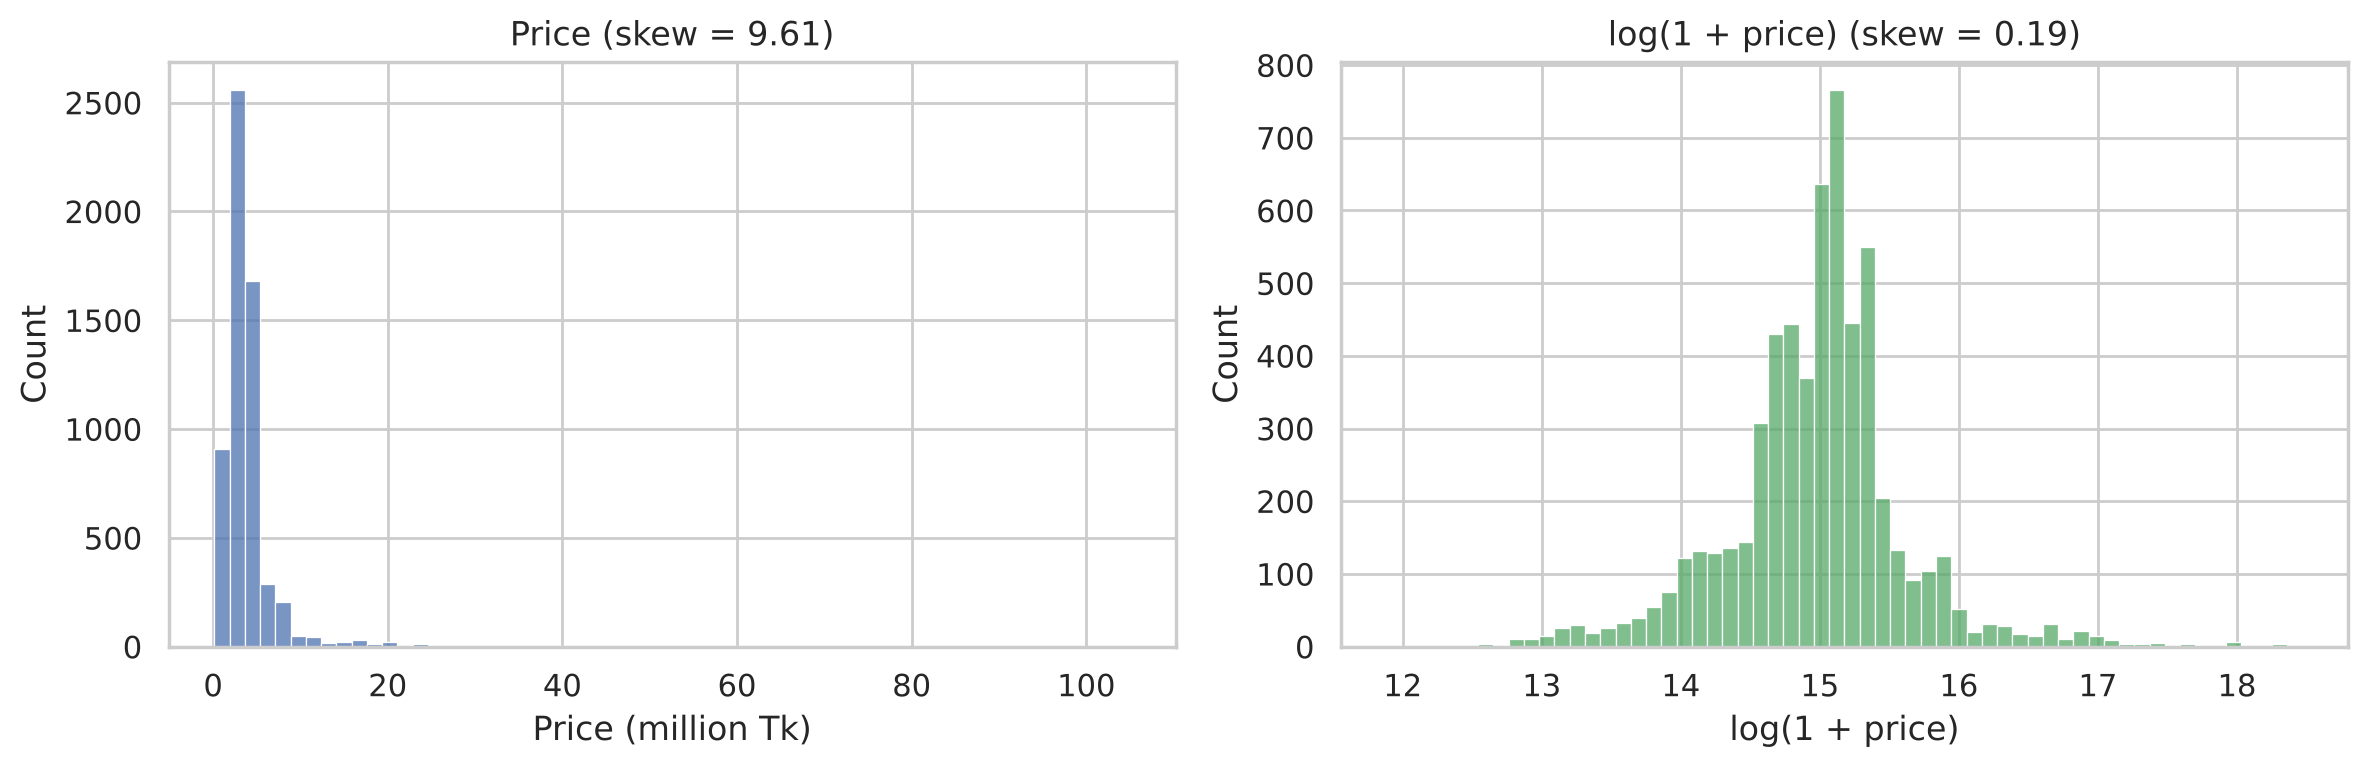

In [11]:
# Plot 1: target distribution - raw vs log scale
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"] / 1e6, bins=60, ax=ax[0], color="#4C72B0")
ax[0].set(title=f"Price (skew = {df['price'].skew():.2f})", xlabel="Price (million Tk)")
sns.histplot(df["log_price"], bins=60, ax=ax[1], color="#55A868")
ax[1].set(title=f"log(1 + price) (skew = {df['log_price'].skew():.2f})", xlabel="log(1 + price)")
plt.tight_layout(); plt.show()

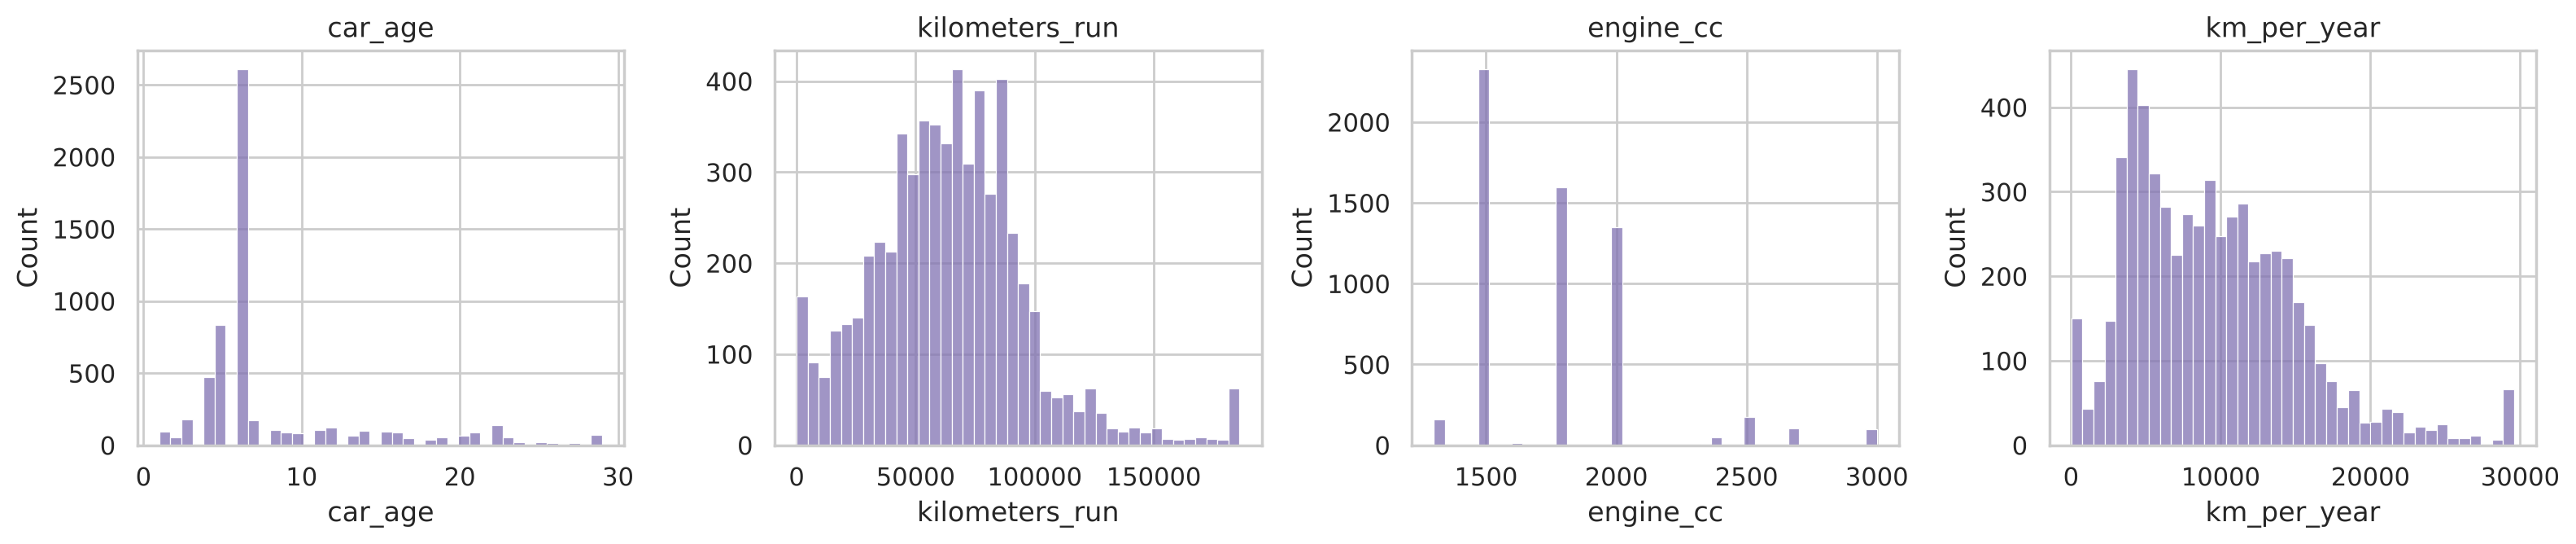

In [12]:
# Plot 2: histograms of the numeric features
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, c in zip(ax, num_cols):
    sns.histplot(df[c], bins=40, ax=a, color="#8172B2")
    a.set_title(c)
plt.tight_layout(); plt.show()

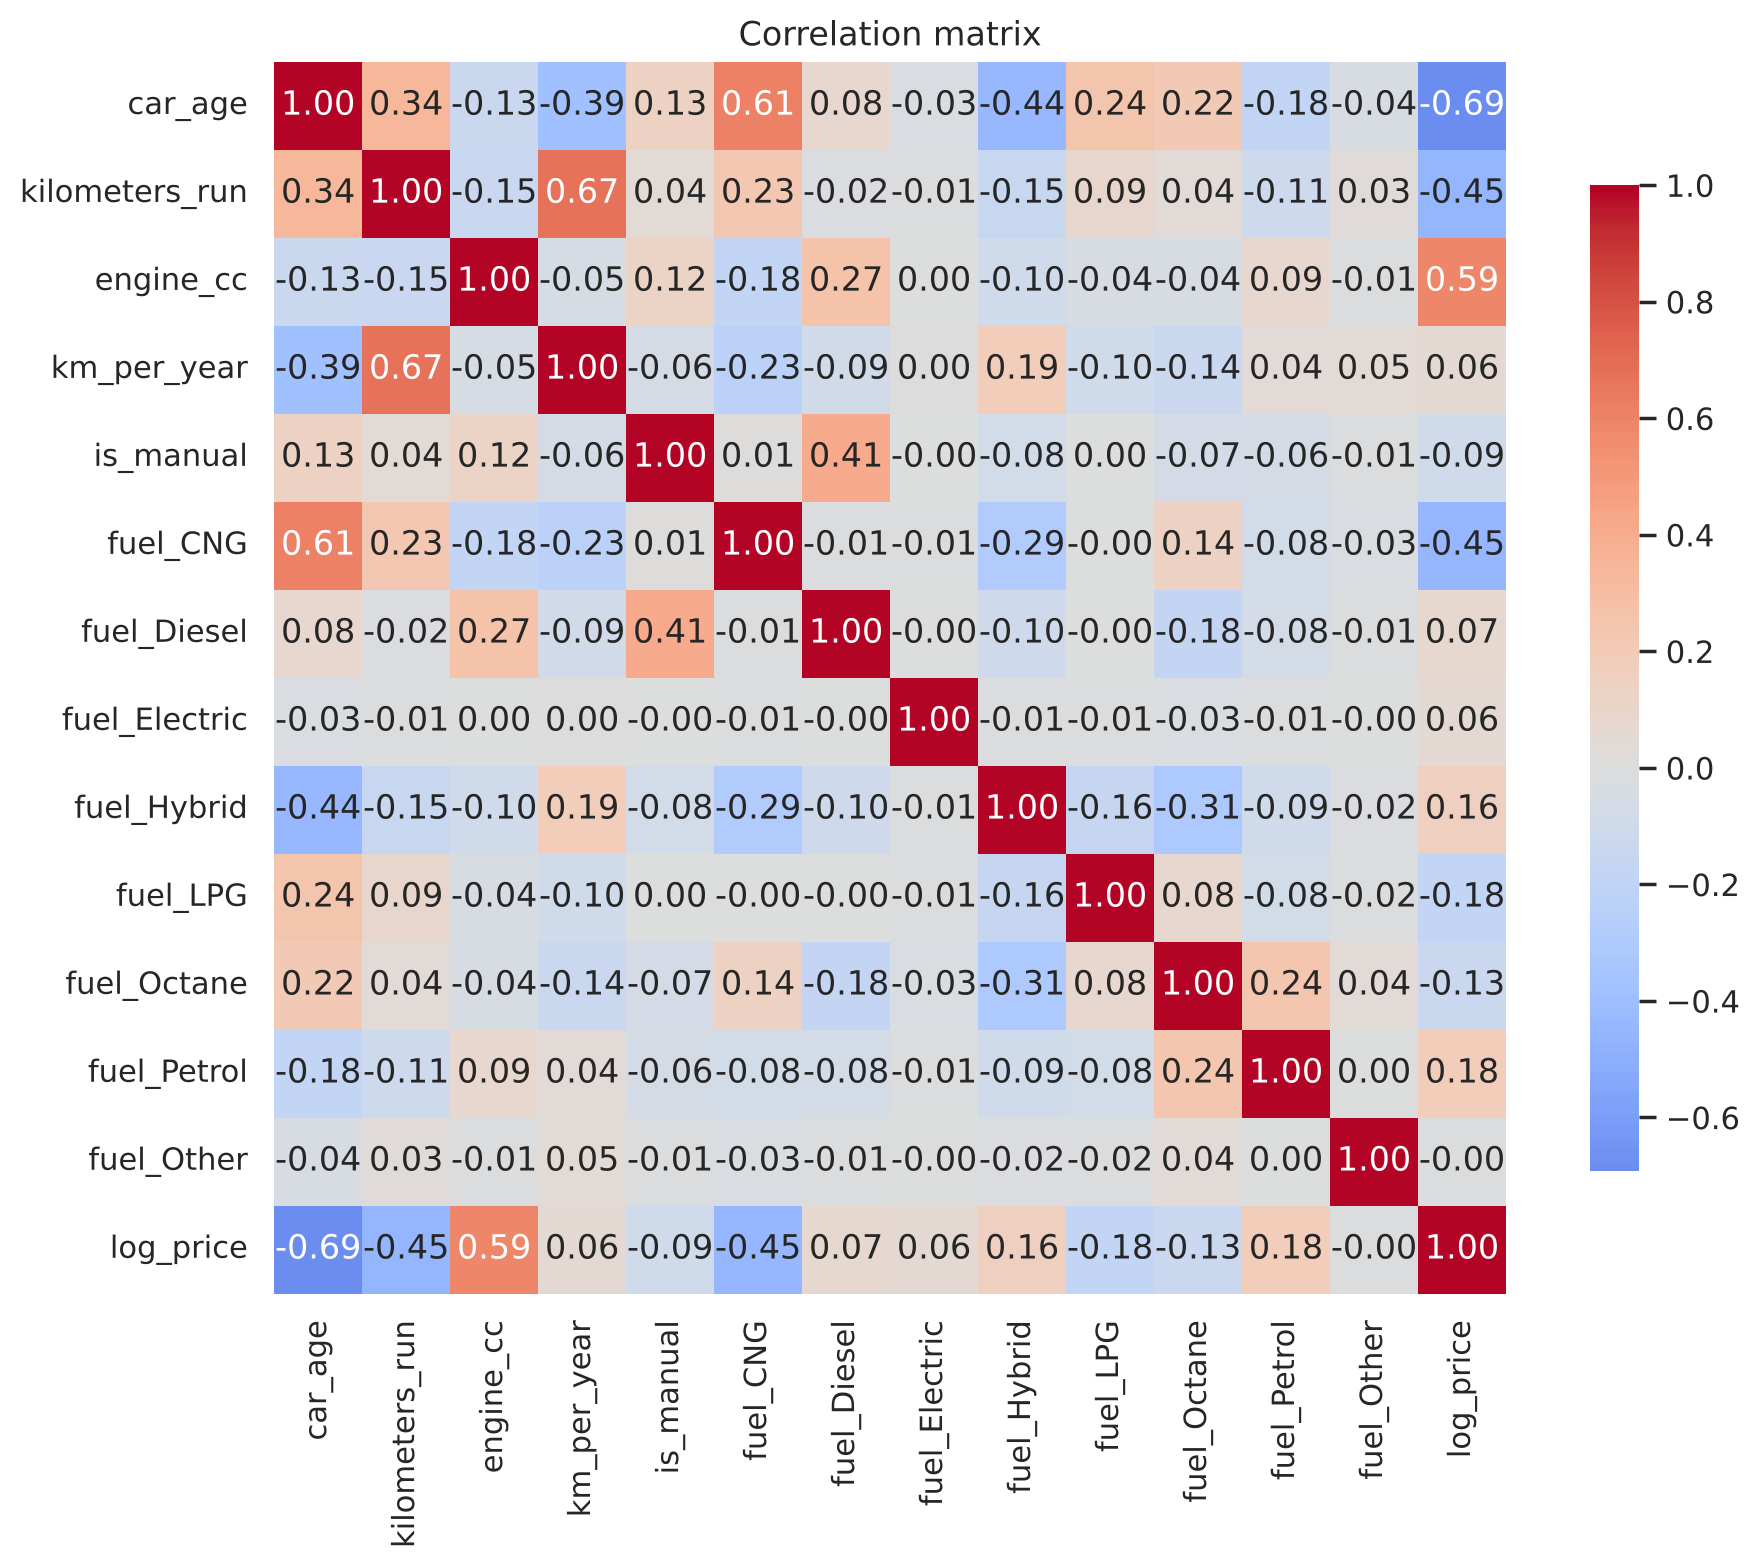

Correlation with log_price (sorted):
car_age          -0.69
engine_cc         0.59
kilometers_run   -0.46
fuel_CNG         -0.45
fuel_Petrol       0.18
fuel_LPG         -0.18
fuel_Hybrid       0.16
fuel_Octane      -0.13
is_manual        -0.09
fuel_Diesel       0.07
km_per_year       0.06
fuel_Electric     0.06
fuel_Other       -0.01


In [13]:
# Plot 3: correlation heatmap (numeric + binary features + target)
corr_cols = num_cols + ["is_manual"] + fuel_cols + ["log_price"]
corr = df[corr_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

print("Correlation with log_price (sorted):")
print(corr["log_price"].drop("log_price").sort_values(key=abs, ascending=False).round(3).to_string())

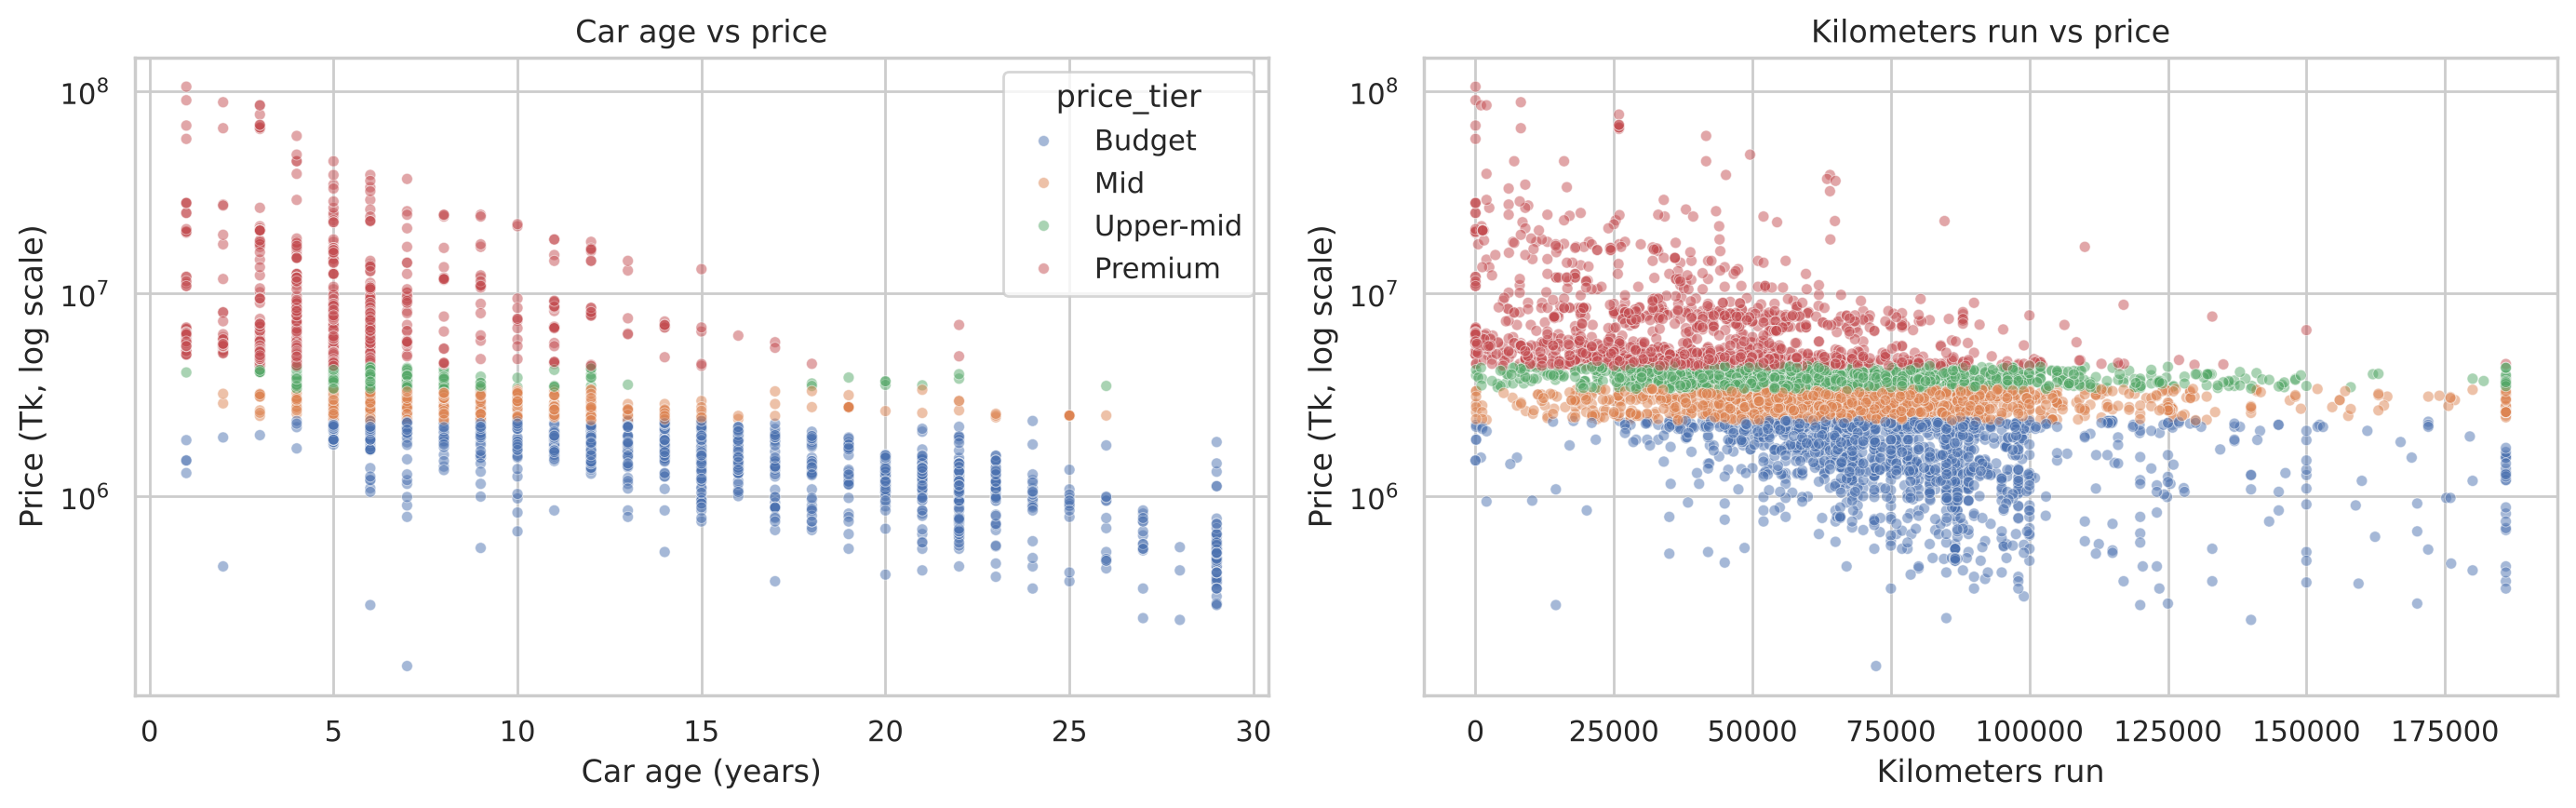

In [14]:
# Plot 4: key relationships with the target
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=df, x="car_age", y="price", hue="price_tier", alpha=0.5, s=18, ax=ax[0])
ax[0].set(yscale="log", title="Car age vs price", xlabel="Car age (years)", ylabel="Price (Tk, log scale)")
sns.scatterplot(data=df, x="kilometers_run", y="price", hue="price_tier", alpha=0.5, s=18, ax=ax[1], legend=False)
ax[1].set(yscale="log", title="Kilometers run vs price", xlabel="Kilometers run", ylabel="Price (Tk, log scale)")
plt.tight_layout(); plt.show()

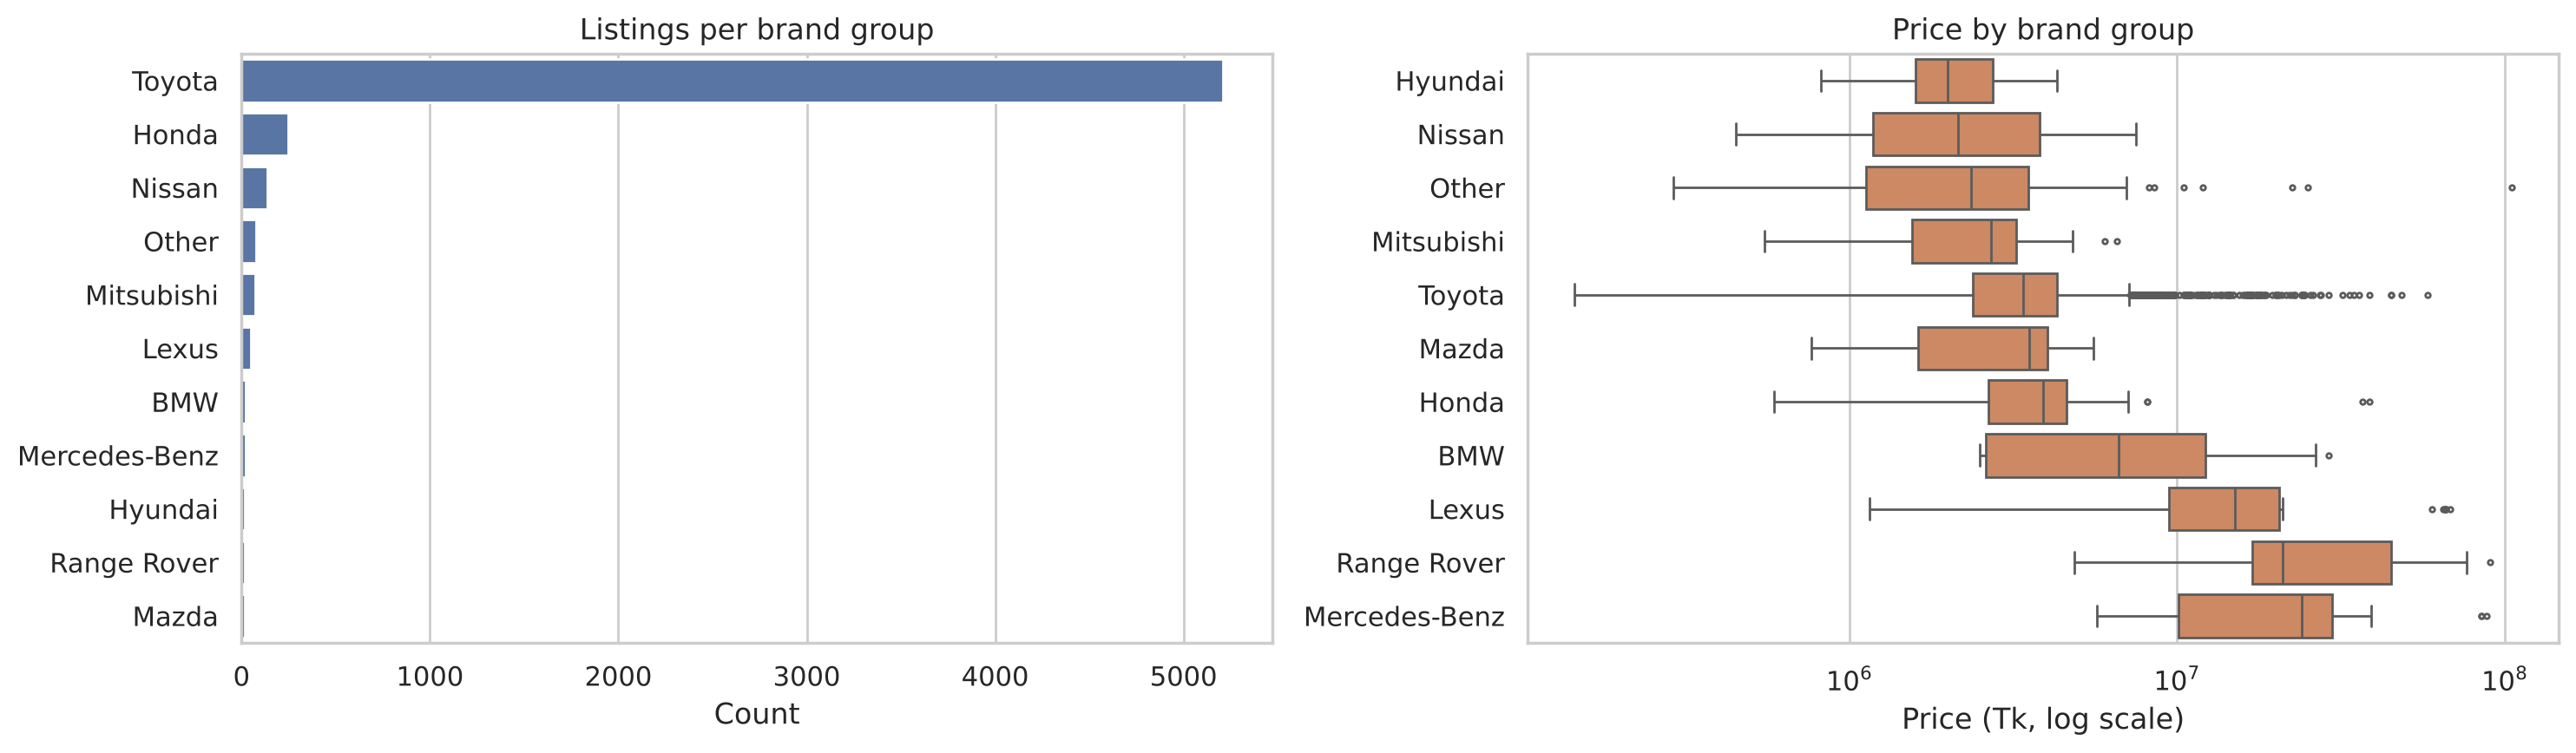

In [15]:
# Plot 5: categorical features - brand frequency and price by brand
order = df.groupby("brand_group")["price"].median().sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.countplot(data=df, y="brand_group", order=df["brand_group"].value_counts().index, ax=ax[0], color="#4C72B0")
ax[0].set(title="Listings per brand group", xlabel="Count", ylabel="")
sns.boxplot(data=df, y="brand_group", x="price", order=order, ax=ax[1], color="#DD8452", fliersize=2)
ax[1].set(xscale="log", title="Price by brand group", xlabel="Price (Tk, log scale)", ylabel="")
plt.tight_layout(); plt.show()

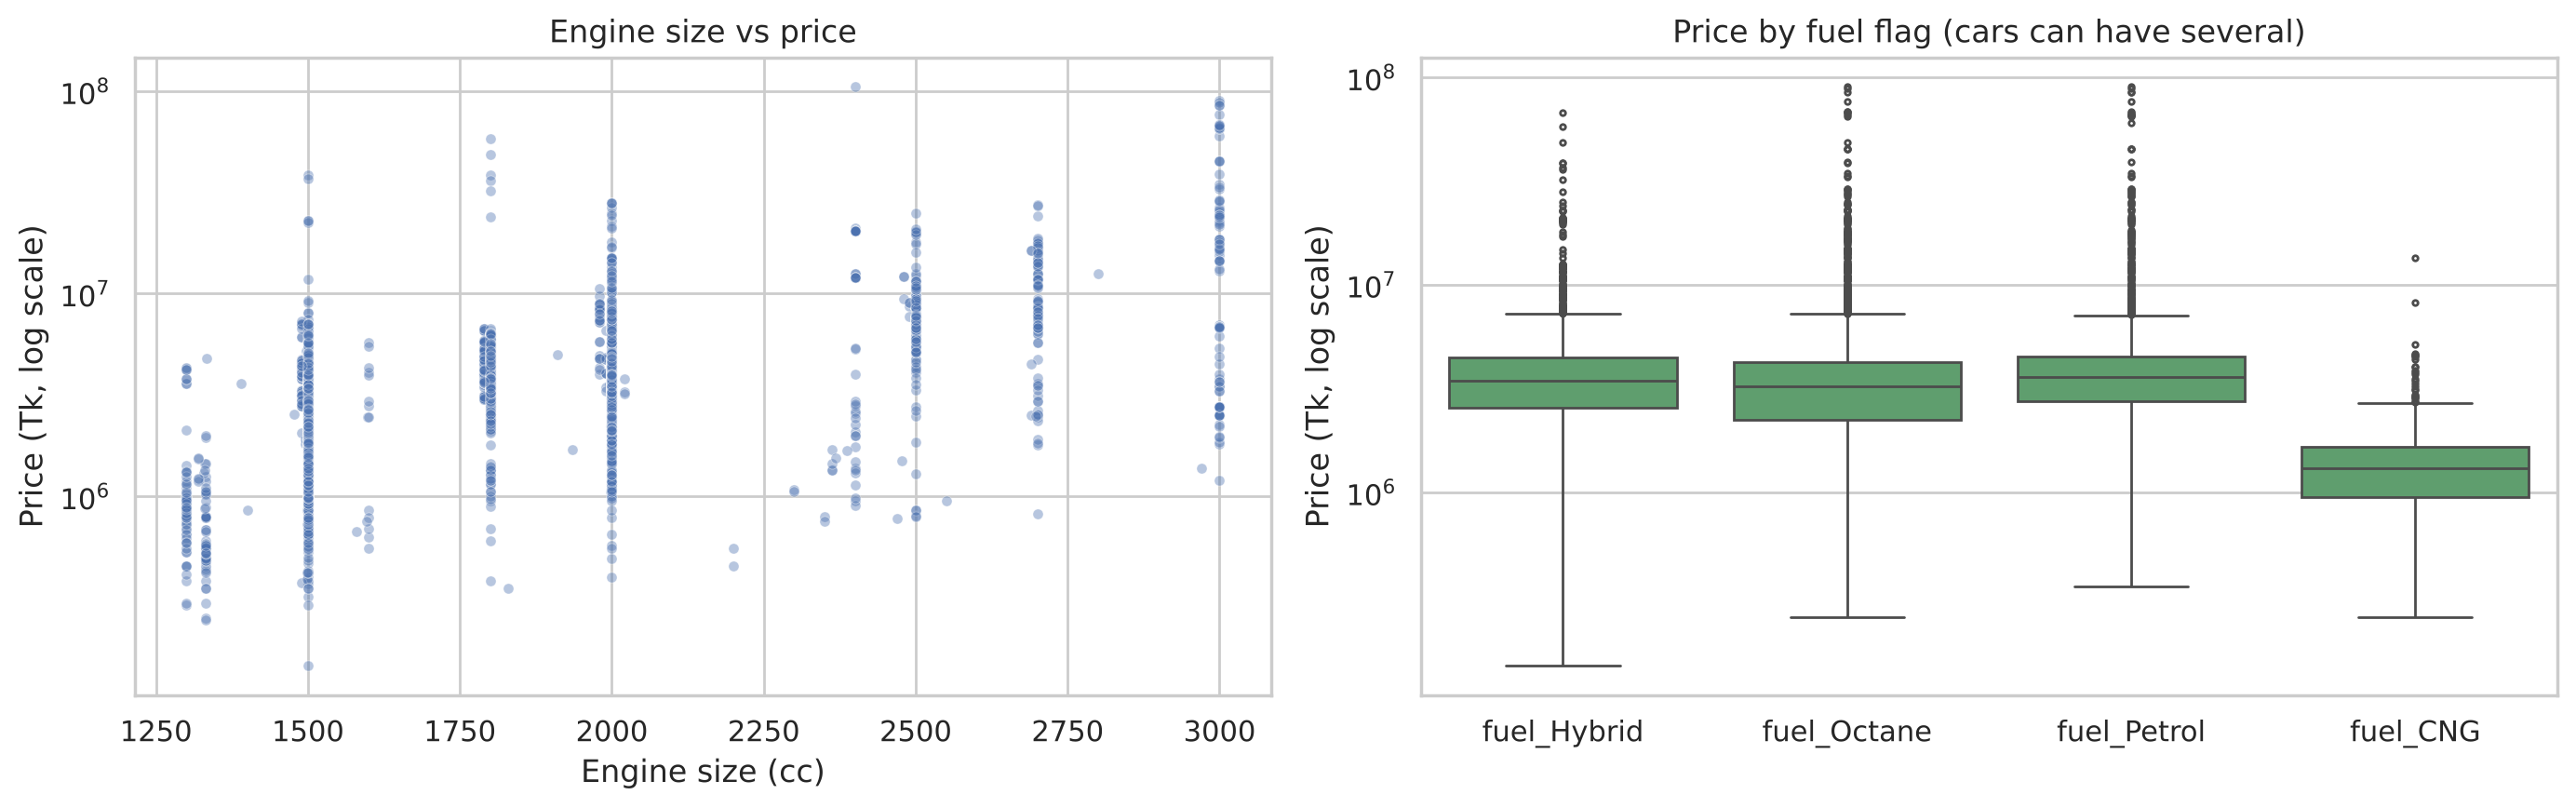

In [16]:
# Plot 6: price by engine size and fuel flag
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=df, x="engine_cc", y="price", alpha=0.4, s=16, ax=ax[0])
ax[0].set(yscale="log", title="Engine size vs price", xlabel="Engine size (cc)", ylabel="Price (Tk, log scale)")
melted = df.melt(id_vars="price", value_vars=["fuel_Hybrid", "fuel_Octane", "fuel_Petrol", "fuel_CNG"], var_name="fuel", value_name="has")
sns.boxplot(data=melted[melted["has"] == 1], x="fuel", y="price", ax=ax[1], color="#55A868", fliersize=2)
ax[1].set(yscale="log", title="Price by fuel flag (cars can have several)", xlabel="", ylabel="Price (Tk, log scale)")
plt.tight_layout(); plt.show()

## 6. Summary of observations

**Dataset snapshot.** The raw file has 5,997 rows and 10 columns. After removing 104 repost duplicates and 2 mis-entered prices, 5,891 listings remain. The final feature matrix has 49 columns and no missing values. The target is `price` (median about 3.38M Tk, range 145K to 105M Tk), so the learning goal is regression.

**Data quality.** There were no `NaN` values, but there were hidden problems: numbers stored as text, 104 duplicate listings, 2 impossible engine sizes (50 cc and 150 cc), 30 old cars reporting near-zero mileage, 1 corrupted `energy_capacity` entry, and 2 prices under 100,000 Tk. All were fixed as described in Section 2.

**Target distribution.** `price` is extremely right-skewed (skewness 9.61) because of a small luxury segment. After the log transform the skewness drops to 0.19, so we will model `log_price` (and convert predictions back to Tk when reporting MAE/RMSE).

**Which features matter most (correlation with `log_price`).**
- `car_age`: strongest, r = -0.69 (older cars are cheaper).
- `engine_cc`: r = +0.59 (bigger engines are pricier).
- `kilometers_run`: r = -0.46, but it is also correlated with age (r = 0.34), so part of its signal overlaps with `car_age`.
- `fuel_CNG`: r = -0.45. This is mostly an age effect: CNG cars have a median age of 20 years vs 6 for the others (CNG vs `car_age` r = 0.61).
- Hybrid, petrol, LPG and octane flags are weak on their own (|r| <= 0.18). `km_per_year` (0.06) and `is_manual` (-0.09) are also weak linearly, although they may still help in non-linear models.

**Categorical features.** `brand` is the most informative categorical: median price is about 3.4M Tk for Toyota but 15M for Lexus, 21M for Range Rover and 24M for Mercedes-Benz. The dataset is dominated by Toyota (88.5% of rows), so most luxury brands have very few samples.

**Problems to keep in mind for modeling.**
- Heavy brand imbalance and a thin luxury tail: errors on expensive cars will dominate raw-Tk metrics (RMSE), so we report both log-scale and Tk-scale metrics.
- `transmission` is nearly constant (0.9% manual), so it carries little information.
- `car_age` and `kilometers_run`/`km_per_year`, and CNG and age, are correlated (multicollinearity), which matters for linear models.
- Relationships look curved on the scatter plots (price drops fastest in the first years), so non-linear models (Random Forest) will probably beat plain Linear Regression.
- Preprocessing choices fit on the full data (scaler, winsorize bounds, imputation medians) must be re-fit on each training split in Task 3 to avoid leakage.

**Next step (Task 2):** run PCA / t-SNE on the standardized feature matrix `X` and color the 2-D embedding by `price_tier` to check whether price levels separate.